# Notebook 2: Two fixes to the heart-rate estimator

Notebook 1 showed two problems:
1. **Wild jumps:** estimates dropped to the 42 bpm floor or spiked to 160-190 bpm.
2. **Sitting got slightly worse** after adding the motion trick.

**Fix 1: stay near where you were.** Heart rate can't teleport. Look only within
+/- `search_bpm` of the previous estimate. If the peak there is weak for several
windows in a row, assume the signal was lost and search the whole range again.

**Fix 2: only use the motion trick when the person is actually moving.**
Below `motion_thresh` the accelerometer spectrum is mostly noise (or may even contain
the pulse itself), and turning it down can remove the real heartbeat.

We change **one thing at a time** and record what happens (an "ablation table").

In [31]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt

In [32]:
DATA_ROOT = r"C:\Users\diya0\Downloads\ppg+dalia\data\PPG_FieldStudy"             # folder where you unzipped PPG-DaLiA (searched recursively)
RESULTS_DIR = "results"
MAKE_FAKE = False                # True = dry run on synthetic data (writes to ../dryrun, never to ../results)
if MAKE_FAKE:
    DATA_ROOT, RESULTS_DIR = "../dryrun/fake_dalia", "../dryrun/results"

FS_PPG, FS_ACC, FS_ACT = 64, 32, 4
WIN_S, SHIFT_S = 8, 2
F_LO, F_HI = 0.7, 3.5
N_FFT = 4096
ALPHA = 0.9
RESET_RATIO = 0.3     # peak near the last estimate must be at least 30% as tall as the tallest peak overall
RESET_AFTER = 5       # ...otherwise after 5 windows in a row (10 s) we search the full range again
DEV_MAX_SUBJECT = 8   # subjects 1..8 = dev (tuning), the rest = test

ACTIVITY_NAMES = {0: "transient", 1: "sitting", 2: "stairs", 3: "table soccer",
                  4: "cycling", 5: "driving", 6: "lunch break", 7: "walking", 8: "working"}
os.makedirs(RESULTS_DIR, exist_ok=True)

## Optional dry run with fake data (same as before)

In [33]:
def make_fake_dataset(root, n_subjects=3, minutes=8, seed=0):
    rng = np.random.default_rng(seed)
    for sid in range(1, n_subjects + 1):
        secs = minutes * 60
        t = np.arange(secs * FS_PPG) / FS_PPG
        hr_t = 105 + 40 * np.sin(2 * np.pi * t / 240 + sid) + 5 * np.sin(2 * np.pi * t / 37)
        phase = 2 * np.pi * np.cumsum(hr_t / 60) / FS_PPG
        act_t = np.repeat([1, 7, 4], secs // 3 * FS_ACT)[: secs * FS_ACT]
        act_t = np.pad(act_t, (0, secs * FS_ACT - len(act_t)), constant_values=4)
        moving = np.repeat(act_t != 1, FS_PPG // FS_ACT)[: len(t)]
        step_hz = 1.6 + 0.4 * np.sin(2 * np.pi * t / 90)
        step_phase = 2 * np.pi * np.cumsum(step_hz) / FS_PPG
        ppg = np.sin(phase) + 0.3 * np.sin(2 * phase)
        ppg = ppg + moving * 1.2 * np.sin(step_phase) + 0.2 * rng.standard_normal(len(t))
        acc = np.stack([moving * 30 * np.sin(step_phase + k) for k in range(3)], axis=1)
        acc = acc[:: FS_PPG // FS_ACC] + 1.5 * rng.standard_normal((secs * FS_ACC, 3))
        n_win = (secs - WIN_S) // SHIFT_S + 1
        label = np.array([hr_t[i * SHIFT_S * FS_PPG: (i * SHIFT_S + WIN_S) * FS_PPG].mean()
                          for i in range(n_win)])
        d = {"signal": {"wrist": {"BVP": ppg[:, None], "ACC": acc}},
             "label": label, "activity": act_t[:, None], "subject": f"S{sid}"}
        os.makedirs(os.path.join(root, f"S{sid}"), exist_ok=True)
        with open(os.path.join(root, f"S{sid}", f"S{sid}.pkl"), "wb") as f:
            pickle.dump(d, f, protocol=2)

if MAKE_FAKE:
    make_fake_dataset(DATA_ROOT)

## 1. Loading, filtering, windowing (unchanged from notebook 1)

In [34]:
def index_pkls(root):
    found = {}
    for dirpath, _, files in os.walk(root):
        for fn in files:
            if fn.startswith("S") and fn.endswith(".pkl"):
                try:
                    found[int(fn[1:-4])] = os.path.join(dirpath, fn)
                except ValueError:
                    pass
    return found

PKL = index_pkls(DATA_ROOT)
SUBJECTS = sorted(PKL)
print("Subjects found:", SUBJECTS)
assert PKL, f"No S*.pkl files under '{DATA_ROOT}'. Check DATA_ROOT."

def load_subject(sid):
    with open(PKL[sid], "rb") as f:
        d = pickle.load(f, encoding="latin1")
    bvp = np.asarray(d["signal"]["wrist"]["BVP"], dtype=float).ravel()
    acc = np.asarray(d["signal"]["wrist"]["ACC"], dtype=float)
    hr = np.asarray(d["label"], dtype=float).ravel()
    act = np.asarray(d["activity"]).ravel().astype(int)
    return bvp, acc, hr, act

def bandpass(x, fs, lo=0.5, hi=4.0, order=4):
    sos = butter(order, [lo, hi], btype="band", fs=fs, output="sos")
    return sosfiltfilt(sos, x)

def make_windows(bvp, acc, hr, act):
    wp, sp = WIN_S * FS_PPG, SHIFT_S * FS_PPG
    wa, sa = WIN_S * FS_ACC, SHIFT_S * FS_ACC
    n = min(len(hr), (len(bvp) - wp) // sp + 1, (len(acc) - wa) // sa + 1)
    ppg_w = np.stack([bvp[i * sp: i * sp + wp] for i in range(n)])
    acc_w = np.stack([acc[i * sa: i * sa + wa] for i in range(n)])
    act_w = np.array([np.bincount(act[i * SHIFT_S * FS_ACT:(i * SHIFT_S + WIN_S) * FS_ACT]).argmax()
                      for i in range(n)])
    return ppg_w, acc_w, hr[:n], act_w

FREQS = np.fft.rfftfreq(N_FFT, 1 / FS_PPG)
BAND = (FREQS >= F_LO) & (FREQS <= F_HI)
FB = FREQS[BAND]
BPM = 60 * FB

def spectrum(x, fs, n_fft):
    x = (x - x.mean()) * np.hanning(len(x))
    return np.fft.rfftfreq(n_fft, 1 / fs), np.abs(np.fft.rfft(x, n=n_fft))

def acc_spectrum_on_grid(acc_win):
    n_fft = N_FFT * FS_ACC // FS_PPG
    total = 0
    for ax in range(3):
        fa, sa = spectrum(acc_win[:, ax], FS_ACC, n_fft)
        total = total + np.interp(FB, fa, sa)
    return total / (total.max() + 1e-12)

Subjects found: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


## 2. Compute spectra once and keep them
The slow part (FFTs) is done once per person and cached (the cache is reused by notebook 3),
so we can try many settings quickly afterwards. Delete the cache file in `results/` if you
change the data or the settings above.

In [35]:
CACHE = os.path.join(RESULTS_DIR, f"spec_cache_{os.path.basename(os.path.normpath(DATA_ROOT))}.pkl")
SPEC = None
if os.path.exists(CACHE):
    with open(CACHE, "rb") as f:
        SPEC = pickle.load(f)
    if sorted(SPEC) == SUBJECTS:
        print("loaded cached spectra from", CACHE)
    else:
        print("cache does not match the subjects found; recomputing")
        SPEC = None
if SPEC is None:
    SPEC = {}
    for sid in SUBJECTS:
        print(f"spectra for S{sid} ...", end=" ")
        bvp, acc, hr, act = load_subject(sid)
        bvp_f = bandpass(bvp, FS_PPG)
        acc_f = np.column_stack([bandpass(acc[:, k], FS_ACC) for k in range(3)])
        ppg_w, acc_w, hr_w, act_w = make_windows(bvp_f, acc_f, hr, act)
        energy = (np.linalg.norm(acc_w, axis=2) ** 2).mean(axis=1)
        lo, hi = np.percentile(energy, [10, 90])
        motion = np.clip((energy - lo) / (hi - lo + 1e-12), 0, 1)
        SPEC[sid] = dict(
            ppg=np.stack([spectrum(w, FS_PPG, N_FFT)[1][BAND] for w in ppg_w]).astype(np.float32),
            acc=np.stack([acc_spectrum_on_grid(w) for w in acc_w]).astype(np.float32),
            motion=motion, energy=energy, hr=hr_w,
            act=np.array([ACTIVITY_NAMES.get(x, str(x)) for x in act_w]))
        print("done")
    with open(CACHE, "wb") as f:
        pickle.dump(SPEC, f)

spectra for S1 ... done
spectra for S2 ... done
spectra for S3 ... done
spectra for S4 ... done
spectra for S5 ... done
spectra for S6 ... done
spectra for S7 ... done
spectra for S8 ... done
spectra for S9 ... done
spectra for S10 ... done
spectra for S11 ... done
spectra for S12 ... done
spectra for S13 ... done
spectra for S14 ... done
spectra for S15 ... done


## 3. The estimator with the two fixes as switches
* `use_acc=False` -> method A (naive)
* `motion_thresh=0, search_bpm=None` -> method B (what you had before, roughly)
* `motion_thresh=T` -> Fix 2
* `search_bpm=S` -> Fix 1

In [36]:
def estimate(ppg_spec, acc_spec, motion, use_acc=True, motion_thresh=0.0, search_bpm=None):
    n = len(ppg_spec)
    est = np.zeros(n)
    prev, weak = None, 0
    for i in range(n):
        s = ppg_spec[i]
        if use_acc and motion[i] > motion_thresh:          # Fix 2: only when clearly moving
            s = s * (1 - ALPHA * motion[i] * acc_spec[i])
        k = int(np.argmax(s))
        if search_bpm is not None and prev is not None:    # Fix 1: stay near the last estimate
            idx = np.where(np.abs(BPM - prev) <= search_bpm)[0]
            local = idx[int(np.argmax(s[idx]))]
            if s[local] < RESET_RATIO * s[k]:               # weak here -> maybe we lost it
                weak += 1
            else:
                weak = 0
            if weak < RESET_AFTER:
                k = int(local)
            else:                                           # lost for 10 s -> search everywhere again
                weak = 0
        est[i] = prev = BPM[k]
    return est

def evaluate(subjects, **kw):
    parts = []
    for sid in subjects:
        S = SPEC[sid]
        est = estimate(S["ppg"], S["acc"], S["motion"], **kw)
        parts.append(pd.DataFrame({"subject": sid, "window": np.arange(len(est)),
                                   "activity": S["act"], "motion": S["motion"],
                                   "hr_true": S["hr"], "est": est}))
    d = pd.concat(parts, ignore_index=True)
    d["err"] = (d["est"] - d["hr_true"]).abs()
    return d

def summarize(d, drop_transient=False):
    if drop_transient:
        d = d[d.activity != "transient"]
    row = {"MAE": d.err.mean()}
    for a in ["sitting", "walking", "cycling", "stairs"]:
        row["MAE " + a] = d[d.activity == a].err.mean()
    row["% err>20bpm"] = 100 * (d.err > 20).mean()
    row["% near 42 floor"] = 100 * (d.est < 45).mean()
    return pd.Series(row)

## 4. Tune each fix on the dev subjects (one at a time)

In [37]:
DEV = [s for s in SUBJECTS if s <= DEV_MAX_SUBJECT]
TEST = [s for s in SUBJECTS if s > DEV_MAX_SUBJECT]
if not TEST:
    print("WARNING: no test subjects found (S9+); using dev subjects for the final table too.")
    TEST = DEV
print("dev:", DEV, "| test:", TEST)

thr_grid = [0.0, 0.1, 0.2, 0.3, 0.4]
rows = {t: summarize(evaluate(DEV, motion_thresh=t)) for t in thr_grid}
thr_table = pd.DataFrame(rows).T.round(2)
thr_table.index.name = "motion_thresh"
print("Fix 2 sweep (dev subjects):")
print(thr_table.to_string())
BEST_T = float(thr_table["MAE"].idxmin())

search_grid = [None, 10, 15, 20, 30]
rows = {str(s): summarize(evaluate(DEV, search_bpm=s)) for s in search_grid}
search_table = pd.DataFrame(rows).T.round(2)
search_table.index.name = "search_bpm"
print("\nFix 1 sweep (dev subjects):")
print(search_table.to_string())
BEST_S = search_table["MAE"].idxmin()
BEST_S = None if BEST_S == "None" else float(BEST_S)
print(f"\nchosen on dev: motion_thresh={BEST_T}, search_bpm={BEST_S}")
thr_table.to_csv(os.path.join(RESULTS_DIR, "02_sweep_motion_thresh.csv"))
search_table.to_csv(os.path.join(RESULTS_DIR, "02_sweep_search_bpm.csv"))

dev: [1, 2, 3, 4, 5, 6, 7, 8] | test: [9, 10, 11, 12, 13, 14, 15]
Fix 2 sweep (dev subjects):
                 MAE  MAE sitting  MAE walking  MAE cycling  MAE stairs  % err>20bpm  % near 42 floor
motion_thresh                                                                                        
0.0            16.71         3.20        21.48        26.10       36.95        28.43             5.64
0.1            16.73         3.19        21.49        26.14       36.95        28.47             5.68
0.2            16.82         3.23        21.49        26.47       37.00        28.65             5.79
0.3            16.93         3.24        21.59        26.93       37.84        28.80             5.88
0.4            17.11         3.25        22.00        27.16       38.15        29.26             5.92

Fix 1 sweep (dev subjects):
              MAE  MAE sitting  MAE walking  MAE cycling  MAE stairs  % err>20bpm  % near 42 floor
search_bpm                                                      

## 5. Ablation table: what each change does
Computed on **test subjects** (not used for choosing the settings).
Columns `% err>20bpm` and `% near 42 floor` measure the two problems directly.

In [38]:
configs = {
    "A  naive": dict(use_acc=False),
    "B  motion-aware": dict(),
    "B + threshold (fix 2)": dict(motion_thresh=BEST_T),
    "B + narrow search (fix 1)": dict(search_bpm=BEST_S),
    "B + both": dict(motion_thresh=BEST_T, search_bpm=BEST_S),
}
results = {name: evaluate(TEST, **kw) for name, kw in configs.items()}
ablation = pd.DataFrame({name: summarize(d) for name, d in results.items()}).T.round(2)
print(ablation.to_string())
ablation.to_csv(os.path.join(RESULTS_DIR, "02_ablation_test_subjects.csv"))

ablation_nt = pd.DataFrame({name: summarize(d, drop_transient=True) for name, d in results.items()}).T.round(2)
print("\nSame table WITHOUT 'transient' windows (activity is changing, so heart rate lags):")
print(ablation_nt.to_string())

                             MAE  MAE sitting  MAE walking  MAE cycling  MAE stairs  % err>20bpm  % near 42 floor
A  naive                   15.50         2.05        25.53        27.37       34.34        29.47             6.59
B  motion-aware            14.46         2.10        23.86        25.76       32.62        26.87             6.38
B + threshold (fix 2)      14.46         2.10        23.86        25.76       32.62        26.87             6.38
B + narrow search (fix 1)  13.44         1.76        20.70        13.49       34.11        25.04             4.74
B + both                   13.44         1.76        20.70        13.49       34.11        25.04             4.74

Same table WITHOUT 'transient' windows (activity is changing, so heart rate lags):
                             MAE  MAE sitting  MAE walking  MAE cycling  MAE stairs  % err>20bpm  % near 42 floor
A  naive                   14.05         2.05        25.53        27.37       34.34        25.56             6.95
B  m

## 6. Charts

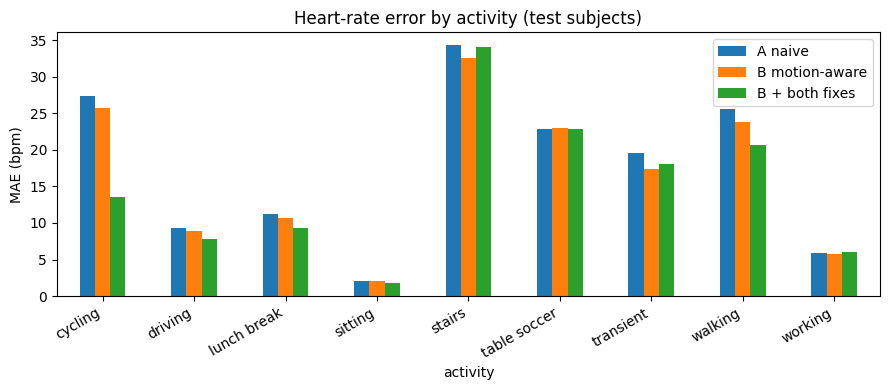

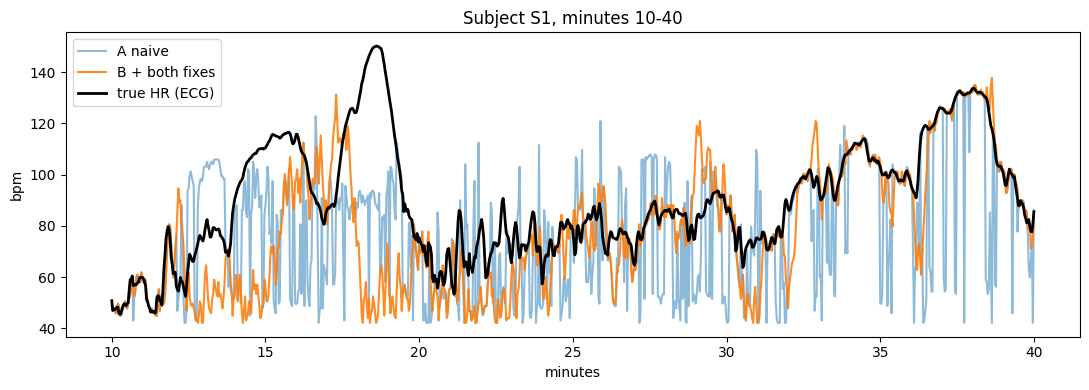

In [39]:
final = results["B + both"]
naive = results["A  naive"]
motion_aware = results["B  motion-aware"]

# Chart 1: MAE per activity
by_act = pd.DataFrame({
    "A naive": naive.groupby("activity").err.mean(),
    "B motion-aware": motion_aware.groupby("activity").err.mean(),
    "B + both fixes": final.groupby("activity").err.mean()})
ax = by_act.plot.bar(figsize=(9, 4))
ax.set_ylabel("MAE (bpm)"); ax.set_title("Heart-rate error by activity (test subjects)")
plt.xticks(rotation=30, ha="right"); plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "02_chart_mae_by_activity.png"), dpi=150)
plt.show()

# Chart 2: zoom on one person, true HR drawn last so it is not hidden
sid0 = SUBJECTS[0]
lo_min, hi_min = 10, 40
a = evaluate([sid0], use_acc=False)
f = evaluate([sid0], motion_thresh=BEST_T, search_bpm=BEST_S)
m = (f.window * SHIFT_S / 60 >= lo_min) & (f.window * SHIFT_S / 60 <= hi_min)
plt.figure(figsize=(11, 4))
plt.plot(a.window[m] * SHIFT_S / 60, a.est[m], alpha=.5, label="A naive")
plt.plot(f.window[m] * SHIFT_S / 60, f.est[m], alpha=.9, label="B + both fixes")
plt.plot(f.window[m] * SHIFT_S / 60, f.hr_true[m], "k", lw=2, label="true HR (ECG)", zorder=5)
plt.xlabel("minutes"); plt.ylabel("bpm"); plt.title(f"Subject S{sid0}, minutes {lo_min}-{hi_min}")
plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "02_chart_zoomed_subject.png"), dpi=150)
plt.show()